# From 2D masks to 3D point clouds (sensor depth)

Chapter 3 core pipeline, reference variant built on **sensor depth** (`depth_bfx`):

1. instance mask → **mask refinement** (boundary erosion, depth-discontinuity and
   per-object depth-outlier filtering — the pixels whose depth cannot be attributed
   to the object);
2. refined mask + depth map + camera intrinsics → back-projection → 3D points;
3. point cloud cleaning in Open3D (voxel downsample + statistical outlier removal);
4. per-object 3D characteristics: centroid, distance to camera, bounding-box
   dimensions, volume, point count;
5. `.ply` export and figures for the thesis.

The whole pipeline lives in `utils/pointcloud.py` — the single source of truth
shared with notebooks 07/08 and the web demo, so every consumer builds clouds
with exactly the same steps and constants. The pipeline is debugged on
**ground-truth masks** first (geometry is isolated from segmentation errors);
swapping in model predictions later only changes the mask source. The
sensor-depth clouds produced here serve as the reference for the monocular
comparison (notebook 07).


In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd
import utils.pointcloud as pc

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
OUT_DIR      = Path("outputs/pointclouds")

N_BATCH_IMAGES = 25   # images for the batch metrics table below

# pipeline constants are owned by utils/pointcloud.py (shared with 07/08 and the demo)
print("cloud pipeline:",
      f"voxel {pc.VOXEL_SIZE} m, SOR ({pc.SOR_NEIGHBORS}, {pc.SOR_STD_RATIO}), "
      f"min points {pc.MIN_POINTS}, depth range ({pc.MIN_DEPTH_M}, {pc.MAX_DEPTH_M}) m")
print("mask refinement:",
      f"erode {pc.ERODE_PX} px, discontinuity window {pc.EDGE_WINDOW} px "
      f"(> max({pc.EDGE_TOL_M} m, {pc.EDGE_TOL_REL:.0%} of depth)), "
      f"depth outliers |z - median| > {pc.DEPTH_MAD_K} MAD")

OUT_DIR.mkdir(parents=True, exist_ok=True)
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
print(f"Test images: {len(coco.getImgIds())}, categories: {list(cat_name.values())}")


cloud pipeline: voxel 0.02 m, SOR (20, 2.0), min points 100, depth range (0.3, 8.0) m
mask refinement: erode 2 px, discontinuity window 5 px (> max(0.15 m, 5% of depth)), depth outliers |z - median| > 3.0 MAD
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Test images: 1287, categories: ['bed', 'chair', 'sofa', 'table', 'desk', 'toilet', 'dresser', 'nightstand', 'bookshelf', 'bathtub']


---
## Pipeline helpers

All geometry goes through `utils/sunrgbd.py` (depth is decoded with the mandatory
bit shift in `sd.read_depth()`, `sd.backproject()` implements the pinhole model
`X = (u−cx)·Z/fx, Y = (v−cy)·Z/fy, Z = depth`) and `utils/pointcloud.py`
(mask refinement, cleaning, characteristics). Per-scene intrinsics are already
stored in the COCO image entries (`fx, fy, cx, cy`).

**Why refine the mask.** An instance mask is a 2D silhouette; the depth of the
pixels on and just inside its border is a mixture of the object and whatever lies
behind it. Back-projected as-is, these pixels become "curtains" of points that
connect the object to the wall or floor behind it, and any bounding box or
volume computed from such a cloud measures the curtain, not the object.
`pc.refine_mask()` therefore drops (1) a 2-px boundary band, (2) pixels on depth
discontinuities (local depth range in a 5×5 window above max(15 cm, 5 % of
depth) — this also catches the smooth ramps of monocular maps) and (3) per-object
depth outliers (|z − median| > 3·MAD — leaked background regions inside coarse
polygon masks). Statistical outlier removal in Open3D then handles the isolated
stragglers that survive.

Coordinates are in the **camera frame**: X right, Y down, Z forward (metres).
Bounding boxes are therefore camera-axis-aligned, not gravity-aligned; the oriented
bounding box (OBB) compensates for most of the difference. Gravity alignment via the
SUN RGB-D tilt matrix is a possible refinement, noted in the text as future work.


In [3]:
def load_frame(img_info: dict):
    """Reads RGB, metric depth and intrinsics for one COCO image entry."""
    rgb = sd.read_rgb(DATASET_ROOT / img_info["file_name"])
    depth = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    intr = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                         cx=img_info["cx"], cy=img_info["cy"])
    return rgb, depth, intr


def metrics_row(pcd: o3d.geometry.PointCloud) -> dict:
    """Scalar 3D characteristics (the centroid vector itself is dropped)."""
    return {k: v for k, v in pc.object_3d_metrics(pcd).items() if k != "centroid"}


def process_image(img_id: int, keep_clouds: bool = False, refine: bool = True):
    """Builds cleaned per-instance clouds and metrics for one test image."""
    info = coco.loadImgs(img_id)[0]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    rgb, depth, intr = load_frame(info)
    rows, clouds = [], []
    for ann in anns:
        mask = coco.annToMask(ann).astype(bool)
        pcd = pc.build_cloud(depth, intr, mask, rgb, refine=refine)
        if len(pcd.points) < pc.MIN_POINTS:
            continue
        row = {"image_id": img_id, "ann_id": ann["id"],
               "class": cat_name[ann["category_id"]],
               "mask_area_px": ann["area"], **metrics_row(pcd)}
        rows.append(row)
        if keep_clouds:
            clouds.append((row, pcd))
    return info, rows, clouds


---
## Single-scene walkthrough

A deterministic sample: the first test image (by id) whose *cleaned* clouds (after
mask refinement and `MIN_POINTS`) cover at least three distinct classes — so the
walkthrough shows several measurable objects, not instances that the refinement
drops as too small.

In [4]:
sample_id = next(
    img_id for img_id in sorted(coco.getImgIds())
    if len({a["category_id"] for a in coco.loadAnns(coco.getAnnIds(imgIds=img_id))}) >= 3
    and len({row["class"] for row in process_image(img_id)[1]}) >= 3)

info, rows, clouds = process_image(sample_id, keep_clouds=True)
print(f"Image {sample_id}: {info['file_name']} ({info['sensor']}, {info['scene_type']})")
sample_df = pd.DataFrame(rows).set_index("ann_id")
sample_df.round(3)

Image 285: kv1/NYUdata/NYU0285/image/NYU0285.jpg (kv1, classroom)


,image_id,class,mask_area_px,n_points,centroid_x,centroid_y,centroid_z,dist_to_camera_m,aabb_w,aabb_h,aabb_d,obb_extent_1,obb_extent_2,obb_extent_3,obb_volume_m3,hull_volume_m3
ann_id,,,,,,,,,,,,,,,,
4651,285,chair,3024.0,350,0.151,0.363,3.462,3.484,0.253,0.340,0.238,0.386,0.296,0.113,0.013,0.004
4652,285,chair,11469.0,771,-0.629,0.597,1.742,1.946,0.494,0.326,0.360,0.573,0.349,0.248,0.050,0.019
4653,285,desk,826.0,142,1.314,0.332,2.559,2.896,0.227,0.153,0.395,0.459,0.096,0.084,0.004,0.001
4654,285,desk,1043.0,113,0.941,0.455,1.832,2.109,0.230,0.106,0.413,0.479,0.076,0.030,0.001,0.000
4664,285,bookshelf,3210.0,875,0.699,-0.127,4.881,4.933,0.223,1.285,0.486,1.319,0.301,0.242,0.096,NaN


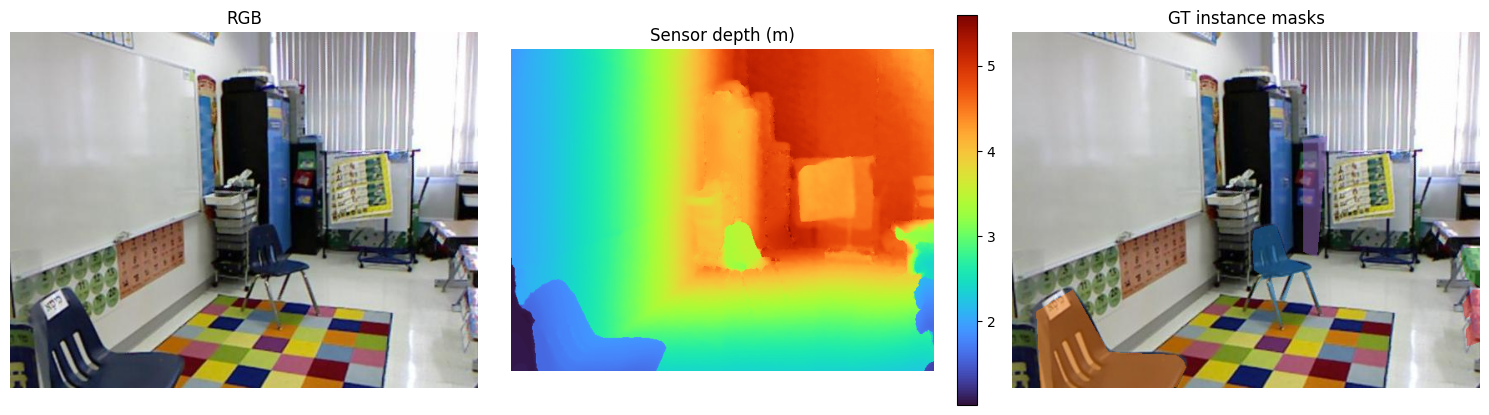

In [5]:
# RGB + depth + instance masks overview of the sample scene
rgb, depth, intr = load_frame(info)
anns = coco.loadAnns(coco.getAnnIds(imgIds=sample_id, iscrowd=False))
cmap = plt.get_cmap("tab10")
# one colour per annotation id, stable across all figures of this scene
ann_color = {ann["id"]: cmap(k % 10) for k, ann in enumerate(anns)}

overlay = rgb.astype(float) / 255.0
for k, ann in enumerate(anns):
    mask = coco.annToMask(ann).astype(bool)
    overlay[mask] = 0.5 * overlay[mask] + 0.5 * np.array(ann_color[ann['id']][:3])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].imshow(rgb); axes[0].set_title("RGB")
im = axes[1].imshow(np.where(depth > 0, depth, np.nan), cmap="turbo")
axes[1].set_title("Sensor depth (m)"); fig.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].imshow(overlay); axes[2].set_title("GT instance masks")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample_id}_2d.png", dpi=150, bbox_inches="tight")
plt.show()

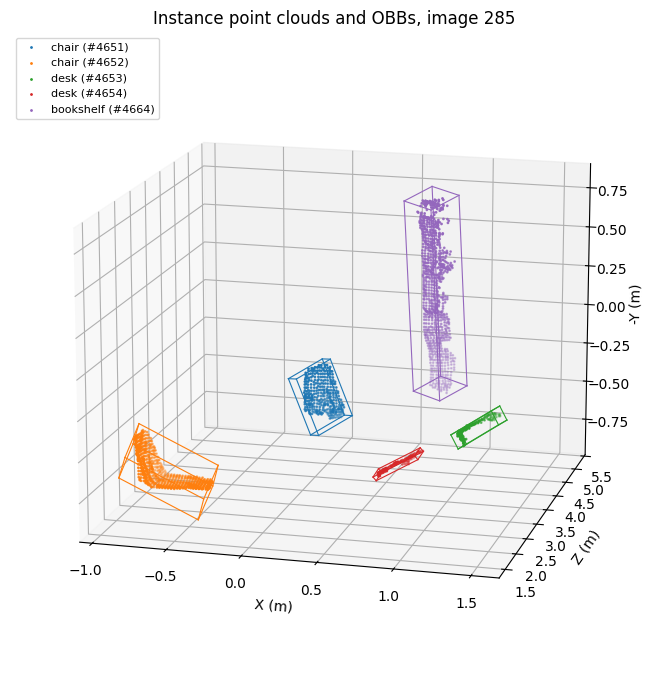

In [6]:
# 3D scatter of the cleaned instance clouds with their OBBs (camera frame; Y flipped for display)
def draw_obb(ax, pcd, color, lw=0.8):
    box = pc.obb_wireframe(pcd)
    if box is None:
        return
    corners, edges = box
    for i, j in edges:
        ax.plot([corners[i, 0], corners[j, 0]], [corners[i, 2], corners[j, 2]],
                [-corners[i, 1], -corners[j, 1]], color=color, lw=lw)


fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for k, (row, pcd) in enumerate(clouds):
    pts = np.asarray(pcd.points)
    ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], s=1,
               color=ann_color[row["ann_id"]], label=f"{row['class']} (#{row['ann_id']})")
    draw_obb(ax, pcd, ann_color[row["ann_id"]])
ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_zlabel("-Y (m)")
ax.set_title(f"Instance point clouds and OBBs, image {sample_id}")
ax.legend(loc="upper left", fontsize=8)
ax.view_init(elev=15, azim=-75)
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample_id}_3d.png", dpi=150, bbox_inches="tight")
plt.show()


### Effect of mask refinement

The same scene with the refinement step switched off (first version of the
pipeline: mask ∩ valid depth, then voxel + SOR) and on. The top row looks along
the camera axis, the bottom row from above — the view in which the "curtains"
between an object and its background are visible as streaks along Z. The
right-hand column colours every point with its RGB pixel: a visible-surface
cloud is far easier to read as a photograph with parallax than as a flat blob.


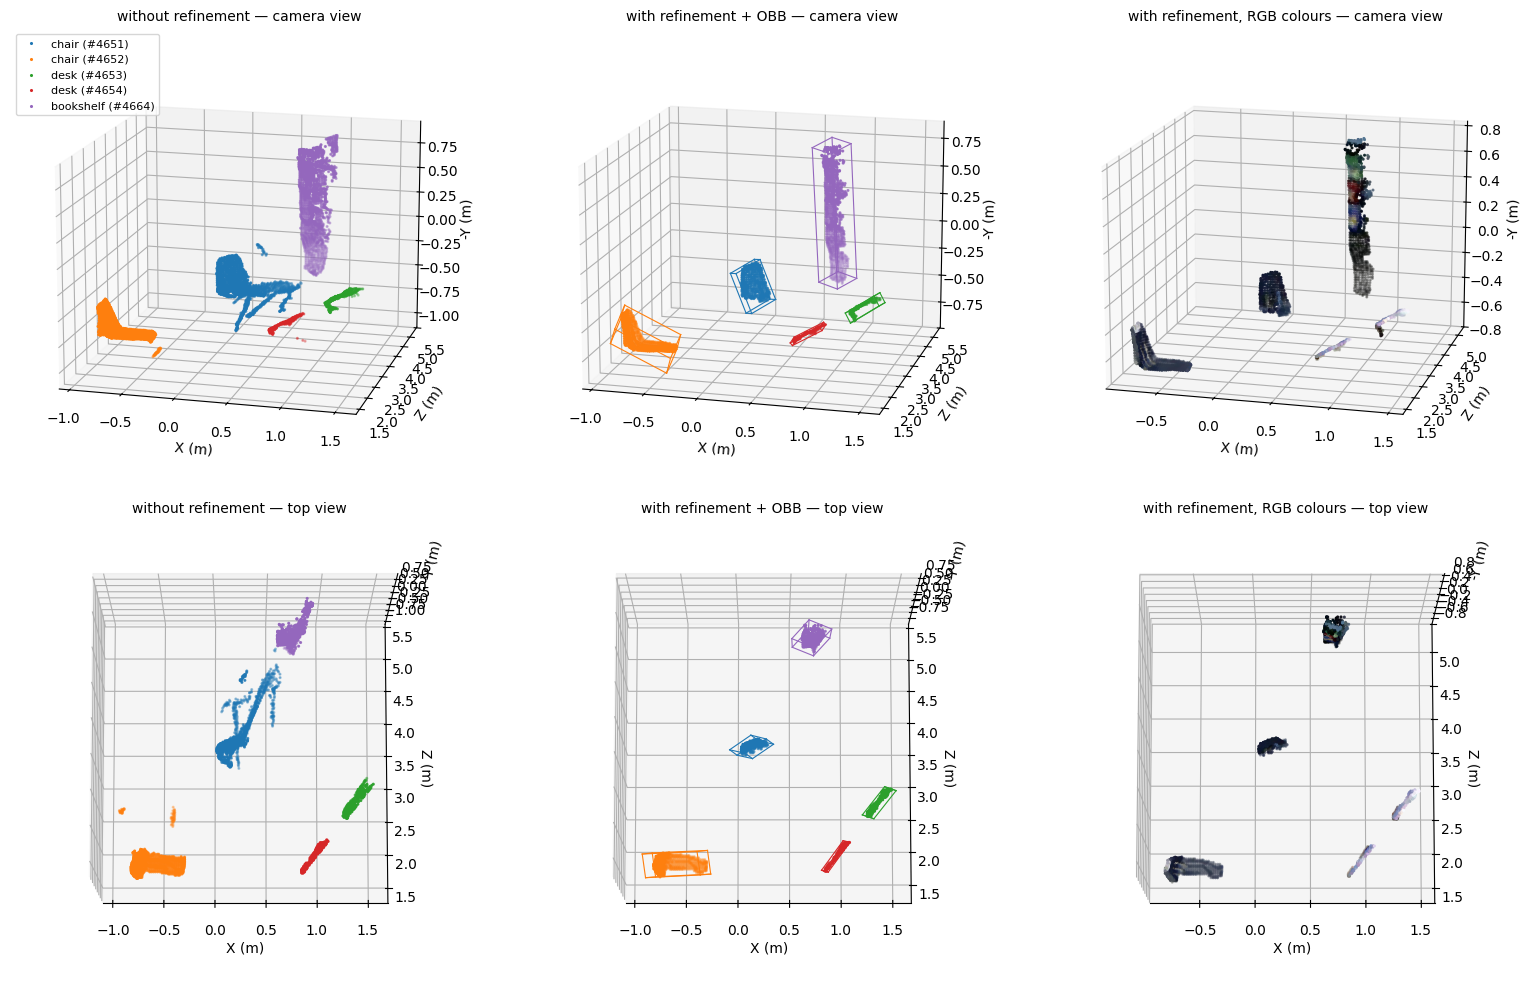

Without vs with mask refinement (same objects; NaN = fewer than MIN_POINTS after refinement):


,class,n_points,obb_extent_1,obb_extent_2,obb_extent_3,hull_volume_m3,n_points_refined,obb_extent_1_refined,obb_extent_2_refined,obb_extent_3_refined,hull_volume_m3_refined
ann_id,,,,,,,,,,,
4651,chair,1197,1.896,0.831,0.511,0.226,350,0.386,0.296,0.113,0.004
4652,chair,998,1.258,0.752,0.358,0.110,771,0.573,0.349,0.248,0.019
4653,desk,231,0.614,0.143,0.097,NaN,142,0.459,0.096,0.084,0.001
4654,desk,162,0.557,0.283,0.063,0.003,113,0.479,0.076,0.030,0.000
4664,bookshelf,1564,1.366,0.675,0.286,0.103,875,1.319,0.301,0.242,NaN


In [7]:
_, rows_raw, clouds_raw = process_image(sample_id, keep_clouds=True, refine=False)
by_ann = {row["ann_id"]: pcd for row, pcd in clouds}

fig, axes = plt.subplots(2, 3, figsize=(16, 10), subplot_kw={"projection": "3d"})
panels = [("without refinement", clouds_raw, False, False),
          ("with refinement + OBB", clouds, True, False),
          ("with refinement, RGB colours", clouds, False, True)]
for col, (title, cl, with_obb, use_rgb) in enumerate(panels):
    for row_i, (elev, azim) in enumerate([(15, -75), (80, -90)]):
        ax = axes[row_i, col]
        for k, (row, pcd) in enumerate(cl):
            pts = np.asarray(pcd.points)
            color = ann_color[row["ann_id"]]
            if use_rgb and pcd.has_colors():
                ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], s=1.5, c=np.asarray(pcd.colors))
            else:
                ax.scatter(pts[:, 0], pts[:, 2], -pts[:, 1], s=1.5, color=color,
                           label=f"{row['class']} (#{row['ann_id']})")
            if with_obb:
                draw_obb(ax, pcd, color)
        ax.set_xlabel("X (m)"); ax.set_ylabel("Z (m)"); ax.set_zlabel("-Y (m)")
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"{title} — {'camera view' if row_i == 0 else 'top view'}", fontsize=10)
axes[0, 0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample_id}_refinement.png", dpi=150, bbox_inches="tight")
plt.show()

# per-object effect on the numbers
cmp = pd.DataFrame(rows_raw).set_index("ann_id")[["class", "n_points", "obb_extent_1", "obb_extent_2", "obb_extent_3", "hull_volume_m3"]]
cmp = cmp.join(sample_df[["n_points", "obb_extent_1", "obb_extent_2", "obb_extent_3", "hull_volume_m3"]],
               rsuffix="_refined", how="left")
print("Without vs with mask refinement (same objects; NaN = fewer than MIN_POINTS after refinement):")
cmp.round(3)


In [8]:
# .ply export: full scene cloud + per-instance clouds
scene_pts, scene_colors = sd.backproject(depth, intr, rgb=rgb, stride=2)
scene_pcd = o3d.geometry.PointCloud()
scene_pcd.points = o3d.utility.Vector3dVector(scene_pts.astype(np.float64))
scene_pcd.colors = o3d.utility.Vector3dVector(scene_colors.astype(np.float64))
scene_pcd = scene_pcd.voxel_down_sample(pc.VOXEL_SIZE)

ply_dir = OUT_DIR / f"sample_{sample_id}"
ply_dir.mkdir(exist_ok=True)
o3d.io.write_point_cloud(str(ply_dir / "scene.ply"), scene_pcd)
for row, pcd in clouds:
    o3d.io.write_point_cloud(str(ply_dir / f"{row['class']}_{row['ann_id']}.ply"), pcd)
print(f"Saved {1 + len(clouds)} .ply files -> {ply_dir}")
print(f"Scene cloud: {len(scene_pcd.points)} points")

Saved 6 .ply files -> outputs/pointclouds/sample_285
Scene cloud: 39338 points


---
## Batch metrics over a test sample

3D characteristics for the first `N_BATCH_IMAGES` test images — the source table
for chapter 3 statistics (later recomputed for the full test set and for
monocular depth).

In [9]:
all_rows = []
batch_ids = sorted(coco.getImgIds())[:N_BATCH_IMAGES]
for n, img_id in enumerate(batch_ids, 1):
    _, rows, _ = process_image(img_id)
    all_rows.extend(rows)
    print(f"  processed {n}/{len(batch_ids)} images, {len(all_rows)} objects", end="\r")
print()

metrics_df = pd.DataFrame(all_rows)
metrics_df.to_csv(OUT_DIR / "object_3d_metrics_sample.csv", index=False)
print(f"Saved {len(metrics_df)} objects -> {OUT_DIR / 'object_3d_metrics_sample.csv'}")
metrics_df.groupby("class")[["n_points", "dist_to_camera_m", "obb_extent_1",
                             "obb_extent_2", "hull_volume_m3"]].median().round(3)

  processed 25/25 images, 73 objects
Saved 73 objects -> outputs/pointclouds/object_3d_metrics_sample.csv


,n_points,dist_to_camera_m,obb_extent_1,obb_extent_2,hull_volume_m3
class,,,,,
bookshelf,1272.5,4.766,1.757,0.441,0.060
chair,296.5,2.688,0.536,0.281,0.005
desk,353.0,2.645,0.632,0.381,0.009
sofa,388.5,2.432,0.601,0.207,0.009
table,416.0,2.504,0.789,0.436,0.014
toilet,887.5,1.475,0.626,0.388,0.030


In [10]:
# how much of each GT mask the refinement keeps (sensor depth, full test split, ~1 min)
kept_frac = []
for img_id in sorted(coco.getImgIds()):
    img_info = coco.loadImgs(img_id)[0]
    _, depth_i, _ = load_frame(img_info)
    for ann in coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False)):
        mask = coco.annToMask(ann).astype(bool)
        if mask.any():
            kept_frac.append(pc.refine_mask(mask, depth_i).sum() / mask.sum())
kept_frac = np.array(kept_frac)
q25, q50, q75 = np.quantile(kept_frac, [0.25, 0.5, 0.75])
print(f"Refinement keeps a median {q50:.1%} of a mask's pixels "
      f"(IQR {q25:.1%}–{q75:.1%}) over {len(kept_frac)} test masks")


Refinement keeps a median 72.0% of a mask's pixels (IQR 56.4%–83.7%) over 5043 test masks


---
## Notes and limitations

- **Visible surfaces only (2.5D).** A single view sees one side of every object:
  a table is its top and one or two legs, a chair its seat and the front of its
  backrest. The clouds are therefore *shells*, not solid models, and never look
  like a CAD object when rotated — this is a property of single-view
  reconstruction, not an error of the pipeline. All 3D characteristics are
  characteristics of the visible part.
- **Depth holes.** Even inpainted `depth_bfx` has zero/invalid pixels on glossy,
  transparent and distant surfaces; those pixels are dropped before back-projection,
  so point counts vary strongly between materials.
- **Mask-boundary tails.** Pixels on instance borders mix foreground and background
  depth and produce streaks ("curtains") towards the background; `pc.refine_mask()`
  removes the border band, the depth discontinuities and per-object depth outliers,
  and `remove_statistical_outlier` the isolated stragglers. The refinement step
  removes a median 28 % of a mask's pixels (IQR 16–44 %, cell above) and can
  push small or distant instances below `MIN_POINTS` — they are then skipped rather than measured badly.
- **Camera-frame boxes.** AABB dimensions depend on camera tilt; OBB extents are
  reported sorted (largest first) and are tilt-invariant up to noise. Gravity
  alignment via the SUN RGB-D tilt matrix is a possible refinement.
- **Volumes are approximations.** Clouds cover only visible surfaces, so the convex
  hull underestimates full object volume for concave shapes and the OBB overestimates
  it; both are still useful for *relative* comparison (sensor vs monocular depth).
